# Testing the HoloViews backend of `mu.pl.embedding` and `mu.pl.scatter`

This notebook is a test battery for the new `backend="holoviews"` option. It complements the pytest tests in `tests/test_muon_plot.py` (what CI runs) in three ways:

1. **Every case runs with both backends.** The matplotlib result is the reference, so a failure is classified: is it something the new backend broke, or a limitation that already exists in `mu.pl`?
2. **It compares what was plotted**, not just that something was returned: the point coordinates must match between the two backends.
3. **It renders the HoloViews plots with Bokeh** and checks the figure: hover tool, legend or colourbar, title, and options that were passed through.

### How to read the verdicts

| Verdict | Meaning |
| --- | --- |
| `OK` | Both backends succeeded and plotted the same points (or, for error cases, the expected error with the expected message) |
| `REGRESSION (holoviews fails)` | Matplotlib works, HoloViews raises: **needs attention** |
| `MISMATCH` | Both work but plotted different coordinates: **needs attention** |
| `both fail (existing limitation)` | Matplotlib fails too, so this is not caused by the new backend. Check that the two messages make sense |
| `holoviews only` | HoloViews works where matplotlib fails (worth a look) |
| `WRONG MESSAGE`, `WRONG EXCEPTION`, `NO ERROR`, `FAIL` | An expected error or check did not behave as expected: **needs attention** |

The last cell raises an error if anything needs attention, so `jupyter nbconvert --execute` can run this notebook as a check.

### How to run it

```bash
git clone https://github.com/ellathomas01/muon.git
cd muon
git checkout holoviews-backend-prototype

uv venv --python 3.12
source .venv/bin/activate
uv pip install --prerelease=allow scanpy hv-anndata holoviews bokeh panel jupyterlab
uv pip install -e .

jupyter lab notebooks/holoviews-backend-testing.ipynb
```

## 0. Setup

/home/ethomas/projects/muon-sandbox/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
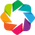

muon        0.1.dev653+gcb4666ee7
mudata      0.4.1
anndata     0.13.4
scanpy      1.13.0a2
holoviews   1.24.0a2
hv-anndata  0.1.2
bokeh       3.10.2rc1


In [1]:
import re
from importlib.metadata import version

import anndata as ad
import holoviews as hv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from bokeh.models import ColorBar, HoverTool
from sklearn.decomposition import PCA

import muon as mu

hv.extension("bokeh")
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 200)

for pkg in ("muon", "mudata", "anndata", "scanpy", "holoviews", "hv-anndata", "bokeh"):
    print(f"{pkg:<11}", version(pkg))

## 1. Test data

- `mdata` has two modalities. `rna` is scanpy's `pbmc68k_reduced`, extended with a layer (`scaled`) and a `.var` column of gene symbols (`symbol`) so that the per-modality options can be tested. `prot` is a **made-up** protein modality built from three marker genes plus noise.
- Extra `.obs` columns cover the dtypes the backend has to handle: a number (`rna:S_score`), text (`rna:bulk_labels`), a boolean (`flag`) and a pandas categorical (`ctype`).
- `X_joint_pca` is a joint embedding stored on the MuData itself.
- `mdata_partial` has a modality (`half`) that only contains **half of the cells**, to test missing values.

In [2]:
rna = sc.datasets.pbmc68k_reduced()
rna.layers["scaled"] = rna.X.copy()
rna.var["symbol"] = "sym_" + rna.var_names

markers = ["CD79A", "CST3", "LYZ"]
rng = np.random.default_rng(0)
values = np.asarray(rna[:, markers].X) + rng.normal(0, 0.3, (rna.n_obs, len(markers)))

prot = ad.AnnData(X=values.astype("float32"))
prot.obs_names = rna.obs_names
prot.var_names = [f"prot_{m}" for m in markers]

prot_half = prot[: rna.n_obs // 2].copy()
prot_half.var_names = [f"half_{m}" for m in markers]

mdata = mu.MuData({"rna": rna, "prot": prot})
mdata.pull_obs(["bulk_labels", "S_score"])
mdata.obs["flag"] = mdata.obs["rna:S_score"] > 0
mdata.obs["ctype"] = pd.Categorical(mdata.obs["rna:bulk_labels"].astype(str))

joint = np.hstack([rna.obsm["X_pca"][:, :10], prot.X])
mdata.obsm["X_joint_pca"] = PCA(n_components=2, random_state=0).fit_transform(joint)

mdata_partial = mu.MuData({"rna": rna, "half": prot_half})

print(mdata)
print(mdata_partial)

MuData object with n_obs × n_vars = 700 × 768
  obs:	'flag', 'ctype'
  obsm:	'X_joint_pca'
  2 modalities
    rna:	700 × 765
      obs:	'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
      var:	'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'symbol'
      uns:	'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts', None, 'scaled'
      obsp:	'connectivities', 'distances'
    prot:	700 × 3
      layers:	None
MuData object with n_obs × n_vars = 700 × 768
  2 modalities
    rna:	700 × 765
      obs:	'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
      var:	'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'symbol'
      uns:	'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
      obsm:	'X_pca'

## 2. The test harness

`case` runs one plotting call with both backends and records a verdict. `expect_error` checks that the HoloViews backend raises the right error with a helpful message.
The helpers `mpl_points` and `hv_points` read the point coordinates back out of each plot, sorted, so the order of the cells does not matter.

In [3]:
rows = []


def mpl_points(ax):
    """Return the (n, 2) point coordinates drawn on a matplotlib axes, sorted."""
    pts = np.vstack([np.asarray(c.get_offsets()) for c in ax.collections]).astype(float)
    return pts[np.lexsort((pts[:, 1], pts[:, 0]))]


def hv_points(plot):
    """Return the (n, 2) point coordinates held by a HoloViews scatter, sorted."""
    pts = np.column_stack([plot.dimension_values(0), plot.dimension_values(1)]).astype(float)
    return pts[np.lexsort((pts[:, 1], pts[:, 0]))]


def point_sets(result):
    """Return one sorted coordinate array per plot in the result of a plotting call."""
    if isinstance(result, hv.Layout):
        return [hv_points(p) for p in result.values()]
    if isinstance(result, list | tuple):
        return [mpl_points(ax) for ax in result]
    if hasattr(result, "collections"):
        return [mpl_points(result)]
    return [hv_points(result)]


def points_match(res_mpl, res_hv):
    """Check that both results contain the same plots with the same point coordinates."""
    a, b = point_sets(res_mpl), point_sets(res_hv)
    return len(a) == len(b) and all(
        x.shape == y.shape and np.allclose(x, y, atol=1e-5) for x, y in zip(a, b, strict=True)
    )


def run(call, backend):
    """Call `call(backend)`; return (result, None) or (None, error text)."""
    try:
        return call(backend), None
    except Exception as e:  # noqa: BLE001
        return None, f"{type(e).__name__}: {str(e)[:100]}"
    finally:
        plt.close("all")


def case(name, call):
    """Run one plotting call with both backends and record how they compare."""
    res_m, err_m = run(call, "matplotlib")
    res_h, err_h = run(call, "holoviews")
    if err_m is None and err_h is None:
        verdict = "OK" if points_match(res_m, res_h) else "MISMATCH"
    elif err_m is None:
        verdict = "REGRESSION (holoviews fails)"
    elif err_h is None:
        verdict = "holoviews only"
    else:
        verdict = "both fail (existing limitation)"
    rows.append({"case": name, "verdict": verdict, "matplotlib": err_m or "ok", "holoviews": err_h or "ok"})


def expect_error(name, call, exc, match):
    """Check that `call()` raises `exc` with a message matching the regular expression `match`."""
    try:
        call()
    except exc as e:
        verdict = "OK" if re.search(match, str(e)) else "WRONG MESSAGE"
        got = f"{type(e).__name__}: {str(e)[:100]}"
    except Exception as e:  # noqa: BLE001
        verdict, got = "WRONG EXCEPTION", f"{type(e).__name__}: {str(e)[:100]}"
    else:
        verdict, got = "NO ERROR", "-"
    rows.append({"case": name, "verdict": verdict, "matplotlib": "-", "holoviews": got})
    plt.close("all")


def emb(data, basis, color=None, **kw):
    """Return a function that calls `mu.pl.embedding` with a given backend."""

    def call(backend):
        extra = {"show": False} if backend == "matplotlib" else {}
        return mu.pl.embedding(data, basis=basis, color=color, backend=backend, **kw, **extra)

    return call


def scat(data, x, y, color=None, **kw):
    """Return a function that calls `mu.pl.scatter` with a given backend."""

    def call(backend):
        extra = {"show": False} if backend == "matplotlib" else {}
        return mu.pl.scatter(data, x=x, y=y, color=color, backend=backend, **kw, **extra)

    return call

## 3. `mu.pl.embedding`: embedding sources

Where the embedding lives: inside a modality, or on the MuData itself, with or without the `X_` prefix.

In [4]:
case("modality embedding: rna:X_umap", emb(mdata, "rna:X_umap", "rna:bulk_labels"))
case("modality embedding, prefix omitted: rna:umap", emb(mdata, "rna:umap", "rna:bulk_labels"))
case("modality embedding with more than 2 dims: rna:X_pca", emb(mdata, "rna:X_pca", "rna:bulk_labels"))
case("joint embedding: X_joint_pca", emb(mdata, "X_joint_pca", "rna:bulk_labels"))
case("joint embedding, prefix omitted: joint_pca", emb(mdata, "joint_pca", "rna:bulk_labels"))

## 4. `mu.pl.embedding`: what `color` can be

No colour, one key, a list, a tuple; text, numeric, boolean and categorical columns.

In [5]:
case("no colour", emb(mdata, "rna:X_umap", None))
case("one categorical (text) column", emb(mdata, "rna:X_umap", "rna:bulk_labels"))
case("one numeric column", emb(mdata, "rna:X_umap", "rna:S_score"))
case("one boolean column", emb(mdata, "rna:X_umap", "flag"))
case("one pandas categorical column", emb(mdata, "rna:X_umap", "ctype"))
case("list of two columns", emb(mdata, "rna:X_umap", ["rna:bulk_labels", "rna:S_score"]))
case("tuple of two columns", emb(mdata, "rna:X_umap", ("rna:bulk_labels", "flag")))
case("list of one column", emb(mdata, "rna:X_umap", ["rna:S_score"]))

## 5. `mu.pl.embedding`: features from modalities, and Muon's per-modality options

A gene, a protein, a gene with the modality prefix, and the per-modality `use_raw`, `layer` and `gene_symbols` options. These are handled by shared code *before* the backend is chosen, so they should behave identically.

In [6]:
case("gene from rna", emb(mdata, "rna:X_umap", "CST3"))
case("protein from prot", emb(mdata, "rna:X_umap", "prot_CST3"))
case("gene with modality prefix", emb(mdata, "rna:X_umap", "rna:CST3"))
case("gene and protein together", emb(mdata, "rna:X_umap", ["CST3", "prot_CST3"]))
case("gene and a categorical column", emb(mdata, "rna:X_umap", ["CST3", "rna:bulk_labels"]))
case("use_raw as a mapping", emb(mdata, "rna:X_umap", "CST3", use_raw={"rna": True, "prot": False}))
case("layer as a mapping", emb(mdata, "rna:X_umap", "CST3", layer={"rna": "scaled", "prot": None}))
case("gene_symbols as a mapping", emb(mdata, "rna:X_umap", "sym_CST3", gene_symbols={"rna": "symbol", "prot": None}))

## 6. `mu.pl.embedding`: other inputs and robustness

A plain `AnnData`, a modality that only covers half of the cells (the rest get missing values), and a colour key that exists nowhere.

In [7]:
case("plain AnnData, embedding and obs column", emb(rna, "X_umap", "bulk_labels"))
case("plain AnnData, embedding without colour", emb(rna, "X_umap", None))
case("modality with half of the cells: feature colour", emb(mdata_partial, "rna:X_umap", "half_CST3"))
case("unknown colour key (error types may differ)", emb(mdata, "rna:X_umap", "no_such_key"))

## 7. `mu.pl.scatter`

Two features or `.obs` columns plotted against each other. `rna:X_umap:1` means the first component of `rna.obsm["X_umap"]` (counting from 1).

In [8]:
case("two features, categorical colour", scat(mdata, "CST3", "prot_CST3", "rna:bulk_labels"))
case("two features, no colour", scat(mdata, "CST3", "prot_CST3", None))
case("two features, numeric colour", scat(mdata, "CST3", "prot_CST3", "rna:S_score"))
case("two features, feature as colour", scat(mdata, "CST3", "prot_CST3", "prot_LYZ"))
case("two features, list of colours", scat(mdata, "CST3", "prot_CST3", ["prot_LYZ", "prot_CD79A"]))
case("obsm components as x and y", scat(mdata, "rna:X_umap:1", "rna:X_umap:2", "rna:bulk_labels"))
case("x and y are .obs columns", scat(mdata, "rna:S_score", "prot_CST3", "flag"))
case("use_raw as a mapping", scat(mdata, "CST3", "LYZ", "rna:bulk_labels", use_raw={"rna": True, "prot": False}))
case("layers as a mapping", scat(mdata, "CST3", "LYZ", "rna:bulk_labels", layers={"rna": "scaled", "prot": None}))
case("plain AnnData, obs columns", scat(rna, "n_counts", "n_genes", "bulk_labels"))

## 8. Errors and messages

The HoloViews backend should fail with a clear message, and only where it really cannot do something. Each case checks the exception type and part of the message.

In [9]:
expect_error(
    "embedding: unknown backend",
    lambda: mu.pl.embedding(mdata, basis="rna:X_umap", color="rna:bulk_labels", backend="plotly"),
    ValueError,
    "Unknown plotting backend",
)
expect_error(
    "scatter: unknown backend",
    lambda: mu.pl.scatter(mdata, x="CST3", y="LYZ", backend="plotly"),
    ValueError,
    "Unknown plotting backend",
)
expect_error(
    "embedding, AnnData: gene as colour is not supported",
    lambda: mu.pl.embedding(rna, basis="X_umap", color="CST3", backend="holoviews"),
    NotImplementedError,
    "only colour by .obs columns",
)
expect_error(
    "embedding, AnnData: use_raw is not supported",
    lambda: mu.pl.embedding(rna, basis="X_umap", color="bulk_labels", use_raw=True, backend="holoviews"),
    NotImplementedError,
    "not supported",
)
expect_error(
    "scatter, AnnData: gene on an axis is not supported",
    lambda: mu.pl.scatter(rna, x="CST3", y="LYZ", backend="holoviews"),
    NotImplementedError,
    "only plot .obs columns",
)
expect_error(
    "scatter, AnnData: layers is not supported",
    lambda: mu.pl.scatter(rna, x="n_counts", y="n_genes", layers="scaled", backend="holoviews"),
    NotImplementedError,
    "not supported",
)
expect_error(
    "embedding: unknown modality in the basis",
    lambda: mu.pl.embedding(mdata, basis="nope:X_umap", backend="holoviews"),
    ValueError,
    "not present",
)
expect_error(
    "embedding: unknown basis",
    lambda: mu.pl.embedding(mdata, basis="X_nope", backend="holoviews"),
    ValueError,
    "not present",
)

## 9. Rendering checks

Here the HoloViews plot is rendered with Bokeh, and the resulting figure is inspected: is the hover tool there, a legend for categorical colours, a colourbar for numeric ones, and do extra keyword arguments reach the plot?

In [10]:
def rendered(plot):
    """Render a HoloViews plot with bokeh and describe what ended up in the figure."""
    fig = hv.render(plot, backend="bokeh")
    return {
        "title": fig.title.text if fig.title else "",
        "hover": any(isinstance(t, HoverTool) for t in fig.tools),
        "colorbar": any(isinstance(r, ColorBar) for r in fig.right),
        "legend": len(fig.legend) > 0,
        "glyph size": getattr(fig.renderers[0].glyph, "size", None),
    }


def render_case(name, make_plot, expected):
    """Render the plot made by `make_plot()` and compare the figure with the `expected` properties."""
    try:
        got = rendered(make_plot())
    except Exception as e:  # noqa: BLE001
        rows.append({"case": name, "verdict": "FAIL", "matplotlib": "-", "holoviews": f"{type(e).__name__}: {e}"[:110]})
        return
    wrong = {k: (v, got.get(k)) for k, v in expected.items() if got.get(k) != v}
    rows.append(
        {
            "case": name,
            "verdict": "OK" if not wrong else "FAIL",
            "matplotlib": "-",
            "holoviews": "as expected" if not wrong else f"expected vs got: {wrong}",
        }
    )


def hv_emb(color, **kw):
    """Make a HoloViews embedding plot."""
    return lambda: mu.pl.embedding(mdata, basis="rna:X_umap", color=color, backend="holoviews", **kw)


render_case(
    "embedding, categorical colour: legend, hover and title",
    hv_emb("rna:bulk_labels"),
    {"hover": True, "legend": True, "colorbar": False, "title": "rna:bulk_labels"},
)
render_case(
    "embedding, numeric colour: colourbar and no legend",
    hv_emb("rna:S_score"),
    {"hover": True, "legend": False, "colorbar": True},
)
render_case(
    "embedding, boolean colour: legend and no colourbar",
    hv_emb("flag"),
    {"legend": True, "colorbar": False},
)
render_case("embedding, no colour: hover only", hv_emb(None), {"hover": True, "legend": False, "colorbar": False})
render_case("embedding, size=3 reaches the glyph", hv_emb("rna:bulk_labels", size=3), {"glyph size": 3})
render_case(
    "embedding, tools=['pan'] replaces the default hover",
    hv_emb("rna:bulk_labels", tools=["pan"]),
    {"hover": False},
)
render_case(
    "scatter, numeric colour: colourbar and hover",
    lambda: mu.pl.scatter(mdata, x="CST3", y="prot_CST3", color="rna:S_score", backend="holoviews"),
    {"hover": True, "colorbar": True, "legend": False},
)
render_case(
    "scatter, categorical colour: legend and hover",
    lambda: mu.pl.scatter(mdata, x="CST3", y="prot_CST3", color="rna:bulk_labels", backend="holoviews"),
    {"hover": True, "colorbar": False, "legend": True},
)

## 10. Other invariants

- The HoloViews backend must not modify the objects it is given (no new `.obs` columns, no entries in `.uns`).
- `mu.pl.scatter` on the two UMAP coordinates must plot the same points as `mu.pl.embedding` on the UMAP.
- Several colours must give one plot per colour, with the same coordinates in each.

In [11]:
def snapshot():
    """Describe the parts of the test objects that plotting could change."""
    return (list(mdata.obs.columns), sorted(mdata.uns), list(rna.obs.columns), sorted(rna.uns), list(prot.obs.columns))


before = snapshot()
mu.pl.embedding(mdata, basis="rna:X_umap", color=["CST3", "rna:bulk_labels"], backend="holoviews")
mu.pl.scatter(mdata, x="CST3", y="prot_CST3", color="rna:bulk_labels", backend="holoviews")
after = snapshot()
rows.append(
    {
        "case": "holoviews leaves the input objects unchanged",
        "verdict": "OK" if before == after else "FAIL",
        "matplotlib": "-",
        "holoviews": "unchanged" if before == after else "the objects were modified",
    }
)

emb_pts = hv_points(mu.pl.embedding(mdata, basis="rna:X_umap", color="rna:bulk_labels", backend="holoviews"))
sca_pts = hv_points(
    mu.pl.scatter(mdata, x="rna:X_umap:1", y="rna:X_umap:2", color="rna:bulk_labels", backend="holoviews")
)
same = emb_pts.shape == sca_pts.shape and np.allclose(emb_pts, sca_pts, atol=1e-5)
rows.append(
    {
        "case": "scatter on the UMAP components plots the same points as embedding",
        "verdict": "OK" if same else "MISMATCH",
        "matplotlib": "-",
        "holoviews": "same points" if same else f"{emb_pts.shape} vs {sca_pts.shape}",
    }
)

three = ["rna:bulk_labels", "flag", "rna:S_score"]
layout = mu.pl.embedding(mdata, basis="rna:X_umap", color=three, backend="holoviews")
sets = [hv_points(p) for p in layout.values()]
ok_layout = len(sets) == 3 and all(np.allclose(sets[0], s, atol=1e-5) for s in sets[1:])
rows.append(
    {
        "case": "three colours: three plots with the same coordinates",
        "verdict": "OK" if ok_layout else "FAIL",
        "matplotlib": "-",
        "holoviews": "three plots, same points" if ok_layout else f"{len(sets)} plots",
    }
)

## 11. Results

The table has one row per case. Rows that need attention are listed separately, and the last cell raises an error if there are any.

In [12]:
df = pd.DataFrame(rows)
print(df["verdict"].value_counts().to_string())
df

verdict
OK                                 52
both fail (existing limitation)     2


,case,verdict,matplotlib,holoviews
0,modality embedding: rna:X_umap,OK,ok,ok
1,"modality embedding, prefix omitted: rna:umap",OK,ok,ok
2,modality embedding with more than 2 dims: rna:X_pca,OK,ok,ok
3,joint embedding: X_joint_pca,OK,ok,ok
4,"joint embedding, prefix omitted: joint_pca",OK,ok,ok
5,no colour,OK,ok,ok
6,one categorical (text) column,OK,ok,ok
7,one numeric column,OK,ok,ok
8,one boolean column,OK,ok,ok
9,one pandas categorical column,OK,ok,ok


In [13]:
fine = ["OK", "holoviews only", "both fail (existing limitation)"]
attention = df[~df["verdict"].isin(fine)]
print(f"{len(df)} cases, {len(attention)} need attention")
attention

54 cases, 0 need attention


,case,verdict,matplotlib,holoviews


In [14]:
assert attention.empty, f"{len(attention)} case(s) need attention, see the table above"
print("All cases fine.")

All cases fine.
